<!-- CONSIGNES -->
# TP2 — Choix des a priori, conjugaison et shrinkage

**Chapitre 2 — Distributions a priori et a posteriori** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

- vérifier les quatre couples conjugués par le calcul direct ;
- quantifier l'information qu'apporte un a priori (taille d'échantillon virtuelle) ;
- faire un **contrôle prédictif a priori** — simuler avant d'avoir les données ;
- observer le **shrinkage** : comment un modèle hiérarchique emprunte de
  l'information entre groupes.

## Ce qui est demandé

1. Parcourir les sections 1 à 4 et commenter les figures obtenues.
2. **Exercice d'élicitation** : reprendre le tableau de sensibilité de la
   section 2 en changeant l'a priori, puis recalculer et comparer.
3. Section 4 : expliquer en trois lignes pourquoi l'intervalle d'un comté
   se rétrécit quand le modèle devient hiérarchique.

## Barème — 10 points

| Critère | Points |
|---|---|
| Vérification des quatre conjugaisons | 2 |
| Tableau de sensibilité recalculé | 3 |
| Contrôle prédictif a priori interprété | 2 |
| Explication du shrinkage (3 lignes) | 3 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# TP2 — Choix des a priori, conjugaison et shrinkage

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

## Objectifs

1. Reconnaître et exploiter les **quatre couples conjugués** classiques.
2. Mesurer **l'information** qu'un prior apporte, et la comparer à celle des données.
3. Faire un **contrôle prédictif a priori** (avant toute donnée) pour valider l'échelle des priors.
4. Voir le **shrinkage** d'un modèle hiérarchique sur un exemple regroupé.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# 1. Les quatre conjugaisons, vérifiées par le calcul

| Vraisemblance | A priori | A posteriori | Mise à jour |
|---|---|---|---|
| $\mathrm{Bin}(n,\theta)$ | $\mathrm{Beta}(\alpha,\beta)$ | $\mathrm{Beta}(\alpha+k,\beta+n-k)$ | on additionne |
| $\mathrm{Poisson}(\lambda)$ | $\mathrm{Gamma}(a,b)$ | $\mathrm{Gamma}(a+\sum y_i,\,b+n)$ | on additionne |
| $\N(\mu,\sigma^2)$ ($\sigma$ connu) | $\N(\mu_0,\tau_0^2)$ | $\N(\mu_n,\tau_n^2)$ | précisions additives |
| $\mathrm{Multinomial}(n,\mathbf p)$ | $\mathrm{Dirichlet}(\boldsymbol\alpha)$ | $\mathrm{Dirichlet}(\boldsymbol\alpha+\mathbf k)$ | on additionne |

Vérifions le cas Gamma-Poisson en comparant la formule close à une intégration numérique.

In [2]:
# --- Gamma-Poisson : comptages d'accidents dans 8 carrefours
y_counts = np.array([2, 0, 3, 1, 5, 2, 1, 4])
a0, b0 = 2.5, 1.0          # prior Gamma(a0, b0) : moyenne 2.5 accidents, assez vague
a1, b1 = a0 + y_counts.sum(), b0 + len(y_counts)
post = stats.gamma(a1, scale=1 / b1)

print(f"donnees  : n = {len(y_counts)}, total = {y_counts.sum()}")
print(f"posterior: Gamma({a1:.1f}, {b1:.1f})  moyenne = {post.mean():.4f}  "
      f"ecart-type = {post.std():.4f}")
print(f"IC 95 %%  : [{post.ppf(.025):.4f} ; {post.ppf(.975):.4f}]")
print(f"P(lambda < 2 | y) = {post.cdf(2):.4f}")

# verification numerique : le posterior non normalise Gamma ameliore par la vraisemblance
lam = np.linspace(1e-4, 8, 120000)
nonnorm = stats.gamma.pdf(lam, a0, scale=1 / b0) * np.prod(
    stats.poisson.pmf(y_counts[:, None], lam[None, :]), axis=0)
nonnorm /= np.trapezoid(nonnorm, lam)
print(f"controle numerique : moyenne = {np.trapezoid(lam*nonnorm, lam):.4f}  "
      f"(formule close : {post.mean():.4f})")

donnees  : n = 8, total = 18
posterior: Gamma(20.5, 9.0)  moyenne = 2.2778  ecart-type = 0.5031
IC 95 %%  : [1.4008 ; 3.3645]
P(lambda < 2 | y) = 0.3079


controle numerique : moyenne = 2.2778  (formule close : 2.2778)


---
# 2. Combien d'information un prior apporte-t-il ?

Un prior Beta$(\alpha_0,\beta_0)$ équivaut à $\alpha_0+\beta_0$ **pseudo-observations**.
Comparons trois priors sur les mêmes données (37 conversions sur 400 visites) : le prior
de droite est un dogme déguisé.

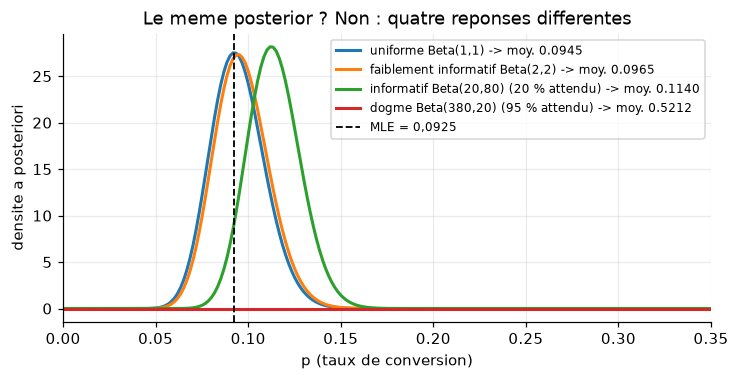

prior                                         moyenne                IC95  P(p>0,10)  poids prior
uniforme Beta(1,1)                             0.0945   [0.0679;0.1249]     0.3393        0.5%
faiblement informatif Beta(2,2)                0.0965   [0.0697;0.1271]     0.3903        1.0%
informatif Beta(20,80) (20 % attendu)          0.1140   [0.0877;0.1432]     0.8379       20.0%
dogme Beta(380,20) (95 % attendu)              0.5212   [0.4866;0.5558]     1.0000       50.0%

Lecture : avec 400 visites, le prior Beta(20,80) apporte 100 pseudo-observations
(20 % du total) et deplace encore la moyenne ; le dogme Beta(380,20) refuse
de voir les donnees : sa moyenne bouge de 0,950 a 0.5212 seulement.


In [3]:
k, n = 37, 400
priors = [("uniforme Beta(1,1)", 1, 1),
          ("faiblement informatif Beta(2,2)", 2, 2),
          ("informatif Beta(20,80) (20 % attendu)", 20, 80),
          ("dogme Beta(380,20) (95 % attendu)", 380, 20)]

th = np.linspace(1e-4, .999, 600)
plt.figure(figsize=(7.6, 3.4))
rows = []
for nom, a0, b0 in priors:
    d = stats.beta(a0 + k, b0 + n - k)
    poids = (a0 + b0) / (a0 + b0 + n)
    rows.append((nom, d.mean(), d.ppf(.025), d.ppf(.975), 1 - d.cdf(.10), poids))
    plt.plot(th, d.pdf(th), lw=2, label=f"{nom} -> moy. {d.mean():.4f}")
plt.axvline(k / n, color="k", ls="--", lw=1.2, label="MLE = 0,0925")
plt.xlabel("p (taux de conversion)"); plt.ylabel("densite a posteriori"); plt.legend(fontsize=8)
plt.title("Le meme posterior ? Non : quatre reponses differentes"); plt.xlim(0, .35); plt.show()

print(f"{'prior':<44}{'moyenne':>9}{'IC95':>20}{'P(p>0,10)':>11}{'poids prior':>13}")
for nom, m, lo, hi, pg, po in rows:
    print(f"{nom:<44}{m:>9.4f}   [{lo:.4f};{hi:.4f}]{pg:>11.4f}{po:>12.1%}")
print()
print("Lecture : avec 400 visites, le prior Beta(20,80) apporte 100 pseudo-observations")
print("(20 % du total) et deplace encore la moyenne ; le dogme Beta(380,20) refuse")
print("de voir les donnees : sa moyenne bouge de 0,950 a", f"{rows[3][1]:.4f}", "seulement.")

---
# 3. Contrôle prédictif a priori : simuler AVANT d'avoir des données

Le test décisif d'un prior : les données qu'il *prédit* sont-elles physiquement possibles ?
Exemple d'un prior mal calibré sur une échelle : on modélise des concentrations dont on sait
qu'elles sont inférieures à 100 mg/L, mais on met un prior vague $\mathrm{Demi\!-\!Normale}(1000)$.

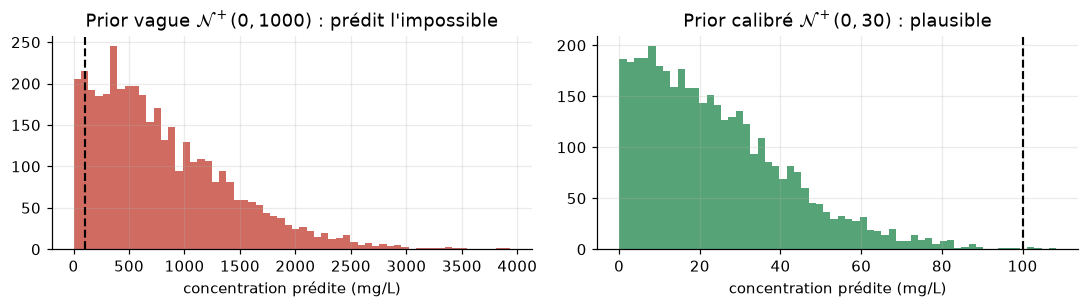

Prior vague  : 91.9% des donnees predites depassent la limite physique de 100 mg/L
Prior calibre: 0.1%

Un prior vague n'est PAS neutre : ici il affirme que des concentrations de 2 000 mg/L
sont normales. Le controle predictif a priori l'aurait revele AVANT tout echantillonnage.


In [4]:
rng = np.random.default_rng(4112)

# --- a priori TROP vague sur l'echelle : on simule ce que le modele predit
pred_vague = np.abs(rng.normal(0, 1000, 4000))
# --- a priori calibre : on sait qu'on est entre 0 et 100
pred_calibre = np.abs(rng.normal(0, 30, 4000))

fig, ax = plt.subplots(1, 2, figsize=(10, 2.9))
ax[0].hist(pred_vague, bins=60, color="#C0392B", alpha=.75)
ax[0].axvline(100, color="k", ls="--", lw=1.4)
ax[0].set_title("Prior vague $\mathcal{N}^+(0, 1000)$ : prédit l'impossible")
ax[0].set_xlabel("concentration prédite (mg/L)")
ax[1].hist(pred_calibre, bins=60, color="#1E8449", alpha=.75)
ax[1].axvline(100, color="k", ls="--", lw=1.4)
ax[1].set_title("Prior calibré $\mathcal{N}^+(0, 30)$ : plausible")
ax[1].set_xlabel("concentration prédite (mg/L)")
plt.tight_layout(); plt.show()

frac = (pred_vague > 100).mean()
print(f"Prior vague  : {frac:.1%} des donnees predites depassent la limite physique de 100 mg/L")
print(f"Prior calibre: {(pred_calibre > 100).mean():.1%}")
print()
print("Un prior vague n'est PAS neutre : ici il affirme que des concentrations de 2 000 mg/L")
print("sont normales. Le controle predictif a priori l'aurait revele AVANT tout echantillonnage.")

---
# 4. Shrinkage hiérarchique : l'information circule entre les groupes

Huit magasins, très différents en volume. Estimés séparément, les petits magasins donnent des
taux extrêmes. Un modèle hiérarchique les **ramène vers la moyenne commune**, d'autant plus
que le groupe est petit.

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [mu, kappa, p]


Sampling 2 chains for 800 tune and 800 draw iterations (1_600 + 1_600 draws total) took 393 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


echantillonnage : 405 s, 1600 tirages retenus
 magasin  visites      MLE  posterieur                  IC95
       0       60    0.017      0.0364   [0.006;0.089]
       1       90    0.044      0.0534   [0.021;0.097]
       2       40    0.075      0.0759   [0.027;0.148]
       3      400    0.087      0.0872   [0.063;0.115]
       4      500    0.110      0.1082   [0.083;0.136]
       5      600    0.110      0.1086   [0.085;0.134]
       6       30    0.000      0.0376   [0.002;0.108]
       7      250    0.076      0.0764   [0.048;0.110]


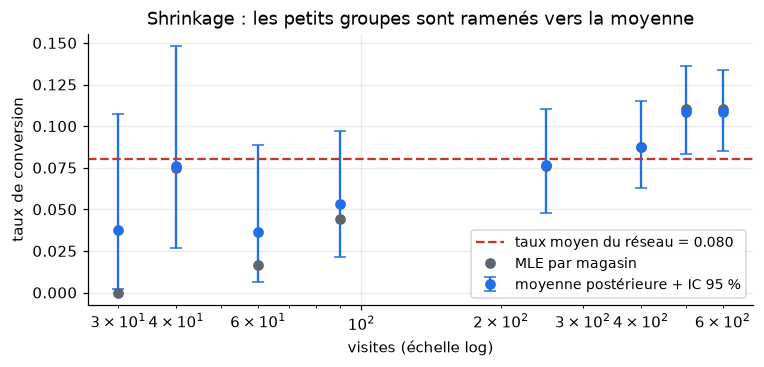

In [5]:
import pymc as pm, arviz as az, time

# --- donnees simulees : 8 magasins, taux de conversion ~ autour de 8 %
vrais = np.array([.05, .06, .04, .09, .10, .12, .03, .08])
visites = np.array([60, 90, 40, 400, 500, 600, 30, 250])
conversions = np.random.default_rng(3).binomial(visites, vrais)

# --- estimateur separe (MLE par magasin)
mle = conversions / visites

t0 = time.time()
with pm.Model() as m:
    mu = pm.Beta("mu", 2, 20)                 # taux moyen du reseau
    kappa = pm.HalfNormal("kappa", 20)        # concentration
    alpha = pm.Deterministic("alpha", mu * kappa)
    beta = pm.Deterministic("beta", (1 - mu) * kappa)
    p = pm.Beta("p", alpha, beta, shape=len(vrais))
    pm.Binomial("obs", n=visites, p=p, observed=conversions)
    idata = pm.sample(draws=800, tune=800, chains=2, cores=1, target_accept=.9,
                      progressbar=False, random_seed=8)
t = time.time() - t0

p_post = idata.posterior["p"].values.reshape(-1, len(vrais))
moy = p_post.mean(axis=0)
lo, hi = np.percentile(p_post, [2.5, 97.5], axis=0)

print(f"echantillonnage : {t:.0f} s, {2*800} tirages retenus")
print(f"{'magasin':>8}{'visites':>9}{'MLE':>9}{'posterieur':>12}{'IC95':>22}")
for i in range(len(vrais)):
    print(f"{i:>8}{visites[i]:>9}{mle[i]:>9.3f}{moy[i]:>12.4f}   [{lo[i]:.3f};{hi[i]:.3f}]")

plt.figure(figsize=(7.8, 3.2))
plt.errorbar(visites, mle, yerr=None, fmt="o", color="#5B6470", label="MLE par magasin")
plt.errorbar(visites, moy, yerr=[moy - lo, hi - moy], fmt="o", color="#1F6FEB",
             capsize=4, label="moyenne postérieure + IC 95 %")
plt.axhline(float(idata.posterior["mu"].mean()), color="#C0392B", ls="--",
            label=f"taux moyen du réseau = {float(idata.posterior['mu'].mean()):.3f}")
plt.xscale("log"); plt.xlabel("visites (échelle log)"); plt.ylabel("taux de conversion")
plt.legend(fontsize=9); plt.title("Shrinkage : les petits groupes sont ramenés vers la moyenne")
plt.show()

**À vous** — Comparez l'écart entre MLE et posterior pour le magasin 7 (30 visites)
et pour le magasin 6 (600 visites). Expliquez en une phrase, en utilisant la notion de
**poids relatif** de la vraisemblance.

---
# Synthèse

* La conjugaison transforme une intégrale en une **addition de paramètres**.
* Un prior se mesure : $\alpha_0+\beta_0$ pseudo-observations face à $n$ observations réelles.
* Un prior se **valide** par un contrôle prédictif a priori — c'est la seule façon de
  déceler un prior qui affirme des choses physiquement impossibles.
* Un modèle hiérarchique **emprunte de l'information** aux groupes voisins : c'est la
  réponse bayésienne au problème des petits effectifs, et la principale raison pour laquelle
  cette approche domine aujourd'hui en biostatistique et en sciences sociales.

**À rendre** : notebook exécuté + une phrase de bilan par section.